<h1><font color="#113D68" size=6>
TINTOlib: de datos tabulares a imágenes sintéticas
</font></h1>

<h1><font color="#113D68" size=5>
Mejorar el aprendizaje profundo sobre datos tabulares mediante imágenes sintéticas
</font></h1>

<h1><font color="#113D68" size=4>
Notebook 05 · Regresión con CNN + MLP y fusión (PyTorch)
</font></h1>

<br><br>

<div style="text-align: right">
<font color="#113D68" size=3>Manuel Castillo-Cara</font><br>
</div>


---
<a id="indice" name="indice"></a>
<h2><font color="#004D7F" size=5>Índice</font></h2>

- [0. Contexto](#section0)
- [1. Configuración](#section1)
- [2. Dataset y particiones](#section2)
- [3. Transformaciones con TINTOlib](#section3)
- [4. Imágenes generadas](#section4)
- [5. Arquitectura CNN + MLP (fusión)](#section5)
- [6. Entrenamiento y resultados](#section6)
- [7. Explicabilidad visual (opcional)](#section7)
- [8. Conclusiones](#section8)
- [9. Ejercicios](#section9)
- [10. Referencias](#section10)


<div class="alert alert-block alert-info">
    
<i class="fa fa-info-circle" aria-hidden="true"></i>
More information about [Manuel Castillo-Cara](https://www.manuelcastillo.eu/)

<div class="alert alert-block alert-info">

<i class="fa fa-info-circle" aria-hidden="true"></i>
Puedes ver más cursos de Inteligencia Artificial, Machine Learning y Deep Learning con descuento en mi [Página Web Personal](https://www.manuelcastillo.eu/udemy/)

<a id="section0" name="section0"></a>
# <font color="#004D7F" size=6>0. Contexto</font>


Los datos tabulares contienen variables numéricas o categóricas, pero no poseen necesariamente una vecindad espacial. **TINTOlib** transforma las observaciones en imágenes para poder utilizar arquitecturas de visión. Distintos métodos producen representaciones diferentes de las mismas variables.

Este ejemplo parte de **regresión sintética controlada**, utiliza **DeepInsight** y estudia una red **CNN + MLP (fusión)**. Primero examinaremos la transformación y sus imágenes; después observaremos cómo las procesa PyTorch. **Una imagen sintética representa una observación de la tabla; no crea un paciente o registro nuevo.**


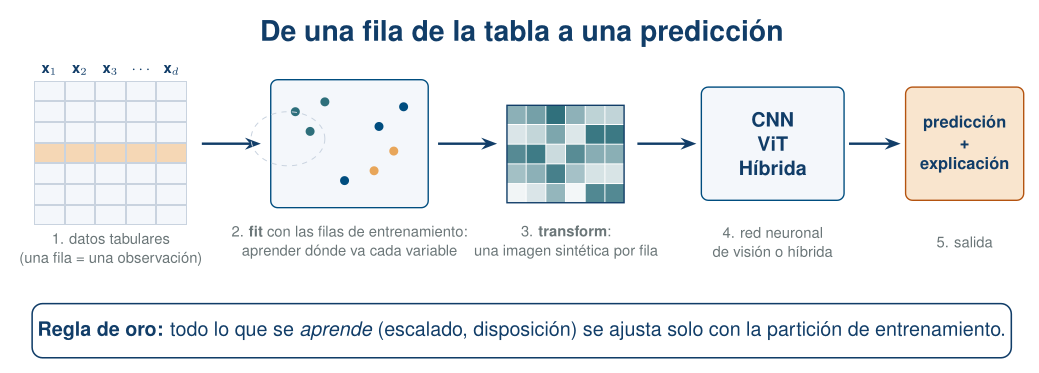

<p style="text-align:center; color:#555555;"><em><strong>Figura 1.</strong> Del registro tabular a la imagen sintética y a la predicción. La disposición se aprende únicamente con TRAIN; el diagrama muestra el proceso general de TINTOlib.</em></p>


<div class="alert alert-info" style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Objetivos de aprendizaje</strong><br>
Identificar qué información recibe <strong>DeepInsight</strong>, interpretar el tamaño y la disposición de las imágenes, comprender el flujo general de <strong>CNN + MLP (fusión)</strong> en PyTorch y leer sus métricas. La explicabilidad se presenta como una actividad visual opcional.
</div>


<div class="alert alert-warning" style="background-color:#fff6e3; border-left:4px solid #cc8a25; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Alcance del taller</strong><br>
Se ejecuta una demostración de pocas épocas y una única partición TRAIN/VALIDATION. No es una comparación científica concluyente entre transformadores ni arquitecturas. El conjunto TEST de cualquier desafío posterior permanece separado.
</div>


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>


<a id="section1" name="section1"></a>
# <font color="#004D7F" size=6>1. Configuración</font>


La primera celda prepara TINTOlib para el entorno de práctica. La siguiente importa las librerías y muestra las opciones que el estudiante puede modificar: `DATASET`, `METODO`, `EPOCAS` y, en el ViT, `PATCH`.

No hace falta entender cada importación: **PyTorch** define la red y entrena sus parámetros; **TINTOlib** genera las imágenes; **scikit-learn** facilita el dataset, las particiones y las métricas.


In [1]:
# Si estás en Google Colab, ejecuta esta celda una sola vez.
# Utilizamos 1.3.2: la release 1.3.3 está pendiente de correcciones.
%pip -q install "TINTOlib==1.3.2"


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import math
from pathlib import Path
from importlib import import_module
from uuid import uuid4
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score, f1_score
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import TensorDataset, DataLoader

SEMILLA = 42
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else
                          "mps" if hasattr(torch.backends, "mps") and torch.backends.mps.is_available()
                          else "cpu")
print("PyTorch:", torch.__version__, "| Dispositivo:", DISPOSITIVO)

# CAMBIA SOLO ESTAS OPCIONES PARA REALIZAR LOS EJERCICIOS
DATASET = "regresion_12"
ARCHIVO_CSV = ""  # Opcional: ruta del CSV propio, con objetivo en última columna
METODO = "DeepInsight"
EPOCAS = 5            # Demostración breve; no es una búsqueda de hiperparámetros
PATCH = 2             # Solo importa para ViT: se explica más adelante

PyTorch: 2.9.1 | Dispositivo: mps


<div class="alert alert-info" style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Cómo interpretar esta salida</strong><br>
Se muestra la versión de PyTorch y el dispositivo elegido (<code>cpu</code>, <code>cuda</code> o <code>mps</code>). Es información de ejecución, <b>no un resultado del modelo</b>. Se utiliza TINTOlib 1.3.2 en estos materiales; la 1.3.3 no es una versión de referencia aprobada.
</div>


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>


<a id="section2" name="section2"></a>
# <font color="#004D7F" size=6>2. Dataset y particiones</font>


El conjunto de **regresión sintética controlada** contiene 12 variables. En este caso se estudia DeepInsight con una red híbrida; el objetivo es comprender cómo se unen dos representaciones de la misma observación, no validar que una fusión mejore el rendimiento.

Primero dividimos las filas en **TRAIN (80 %)** y **VALIDATION (20 %)**. Imputación, codificación, escalado y parámetros aprendidos se ajustan exclusivamente con TRAIN; al generar imágenes de VALIDATION se reutiliza el transformador ya ajustado.


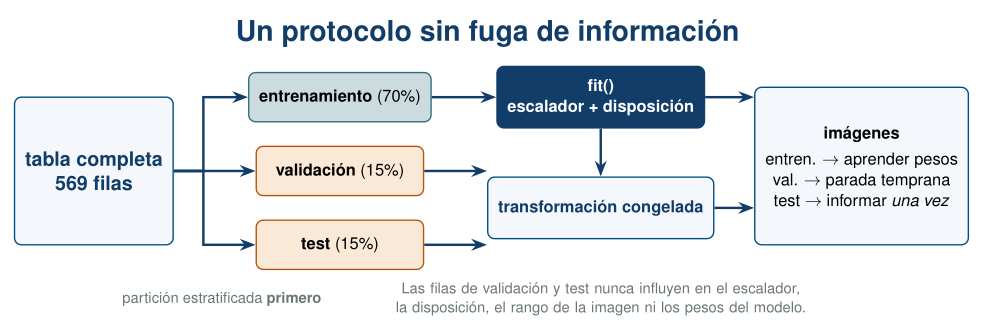

<p style="text-align:center; color:#555555;"><em><strong>Figura 2.</strong> Protocolo de separación de datos. Aunque el diagrama incluya TEST para ilustrar una evaluación completa, este notebook trabaja solo con TRAIN y VALIDATION.</em></p>


In [3]:
from sklearn.datasets import load_diabetes, load_breast_cancer, load_wine, make_regression

if ARCHIVO_CSV:
    tabla = pd.read_csv(ARCHIVO_CSV)
    id_datos = Path(ARCHIVO_CSV).stem
elif DATASET == "diabetes":
    tabla = load_diabetes(as_frame=True).frame.copy()
    id_datos = "Diabetes"
elif DATASET == "cancer":
    tabla = load_breast_cancer(as_frame=True).frame.copy()
    id_datos = "Breast Cancer Wisconsin"
elif DATASET == "wine":
    tabla = load_wine(as_frame=True).frame.copy()
    id_datos = "Wine"
elif DATASET in ("regresion_8", "regresion_12"):
    n = int(DATASET.split("_")[-1])
    X, y = make_regression(n_samples=360, n_features=n, n_informative=max(4, n // 2),
                           noise=20, random_state=SEMILLA)
    tabla = pd.DataFrame(X, columns=[f"x{j+1}" for j in range(n)])
    tabla["target"] = y
    id_datos = f"Regresión sintética ({n} variables)"
else:
    raise ValueError(f"Dataset no reconocido: {DATASET}")

TAREA = "regression"  # regression o classification
objetivo = tabla.columns[-1]
print(id_datos, "| Observaciones:", len(tabla), "| Variables:", len(tabla.columns)-1)
display(tabla.head(3))

tr, va = train_test_split(tabla, test_size=0.20, random_state=SEMILLA,
                          stratify=tabla[objetivo] if TAREA == "classification" else None)
tr, va = tr.reset_index(drop=True), va.reset_index(drop=True)
X_tr = pd.get_dummies(tr.drop(columns=objetivo), dummy_na=True, dtype=float)
X_va = pd.get_dummies(va.drop(columns=objetivo), dummy_na=True, dtype=float).reindex(
    columns=X_tr.columns, fill_value=0)
X_tr, X_va = X_tr.replace([np.inf, -np.inf], np.nan), X_va.replace([np.inf, -np.inf], np.nan)
medianas = X_tr.median().fillna(0)  # Exclusivamente TRAIN
X_tr, X_va = X_tr.fillna(medianas), X_va.fillna(medianas)

if TAREA == "classification":
    cod_y = LabelEncoder().fit(tr[objetivo])
    y_tr, y_va = cod_y.transform(tr[objetivo]), cod_y.transform(va[objetivo])
    num_salidas, escala_y = len(cod_y.classes_), None
else:
    escala_y = StandardScaler().fit(tr[[objetivo]])  # Solo TRAIN
    y_tr = escala_y.transform(tr[[objetivo]]).ravel()
    y_va = escala_y.transform(va[[objetivo]]).ravel()
    num_salidas = 1

# Normalización SOLO de la rama MLP; la propia TINTOlib ajusta su escalador interno.
escala_tab = StandardScaler().fit(X_tr)
tab_tr = torch.tensor(escala_tab.transform(X_tr), dtype=torch.float32)
tab_va = torch.tensor(escala_tab.transform(X_va), dtype=torch.float32)
y_tr_tensor = torch.tensor(y_tr, dtype=torch.long if TAREA == "classification" else torch.float32)
y_va_tensor = torch.tensor(y_va, dtype=torch.long if TAREA == "classification" else torch.float32)
print("TRAIN:", len(tr), "| VALIDATION:", len(va), "| Variables finales:", X_tr.shape[1])

Regresión sintética (12 variables) | Observaciones: 360 | Variables: 12


,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11,x12,target
0,0.346710,-0.113128,-0.756764,0.232787,-1.299216,-2.189922,1.194592,-0.032281,-1.840078,0.123078,2.511557,0.640543,75.340106
1,0.113270,-0.447322,0.852774,0.067856,1.281016,0.484733,-0.846357,-0.668144,0.919229,1.080048,-1.438278,1.873298,138.580891
2,0.958386,-0.297482,0.194052,0.320786,1.311984,-1.270061,0.286956,1.074318,0.229075,0.904018,0.051661,0.224340,145.208316


TRAIN: 288 | VALIDATION: 72 | Variables finales: 12


<div class="alert alert-info" style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Qué muestran las salidas</strong><br>
La tabla inicial permite reconocer las variables y el objetivo; las líneas de consola indican el número de observaciones, la dimensión final tras el preprocesamiento y el tamaño de cada partición. Estos tamaños sirven para comprobar que el entrenamiento y la validación no comparten filas.
</div>


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>


<a id="section3" name="section3"></a>
# <font color="#004D7F" size=6>3. Transformaciones con TINTOlib</font>


Esta es la etapa central del ejemplo. El parámetro `METODO` selecciona la transformación desde un pequeño registro. Todos los casos siguen una idea común: **aprender con TRAIN y transformar TRAIN y VALIDATION sin reajustar el método**.

| Método | Idea principal | Qué observar |
|---|---|---|
| **TINTO** | Coloca variables en una disposición 2D; admite desenfoque. | Vecindad y distribución de intensidades. |
| **IGTD** | Optimiza una disposición de variables en una rejilla. | Forma `filas×columnas` y píxeles vacíos. |
| **DeepInsight / Fotomics** | Producen disposiciones e intensidades según sus respectivos algoritmos. | Diferencias de representación con igual tabla. |
| **REFINED** | Organiza espacialmente variables; necesita MPI. | Geometría y coste de ejecución. |
| **BIE** | Codifica valores con una representación visual distinta. | Tamaños y estructuras no necesariamente cuadradas. |

**Método seleccionado:** `DeepInsight`. Con 12 variables y `image_dim=4`, DeepInsight genera imágenes de **4×4**; las posiciones sin variable no son datos originales. Al cambiar de método, conviene observar primero la imagen antes de comparar métricas.


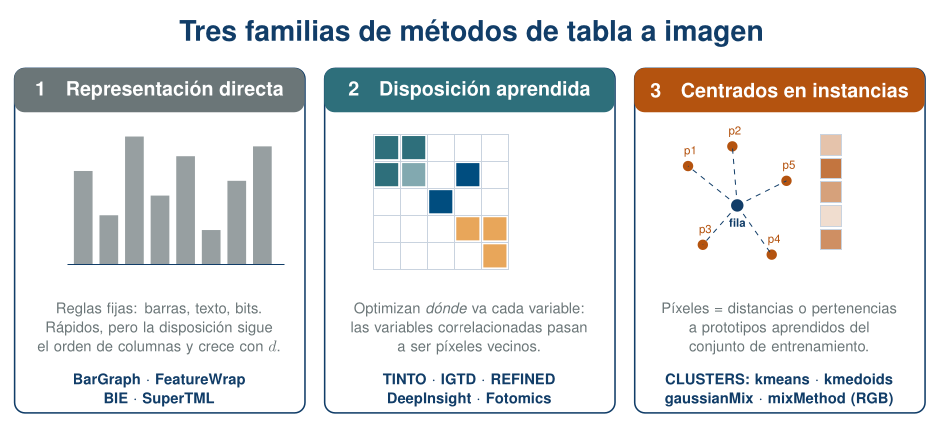

<p style="text-align:center; color:#555555;"><em><strong>Figura 3.</strong> Familias de representación tabular-a-imagen. No todos los codificadores tienen la misma interpretación de un píxel.</em></p>


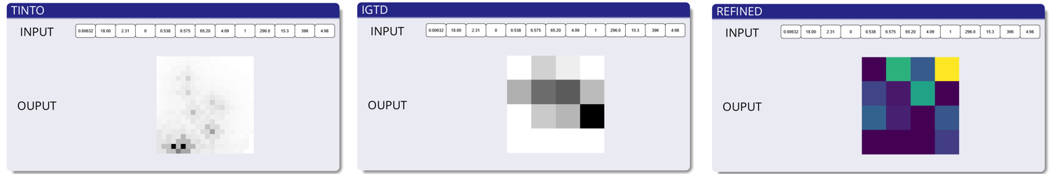

<p style="text-align:center; color:#555555;"><em><strong>Figura 4.</strong> Tres diseños visuales distintos para datos tabulares. La figura ilustra diferencias de organización, no resultados predictivos.</em></p>


<div class="alert alert-warning" style="background-color:#fff6e3; border-left:4px solid #cc8a25; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Dependencias y significado de los píxeles</strong><br>
REFINED es una ampliación opcional porque requiere MPI. CLUSTERS representa prototipos o componentes, no variables individuales. Para las demás opciones también hay que consultar sus parámetros y posibles restricciones antes de usar un método nuevo.
</div>


La siguiente celda muestra cómo elegir un método y sus parámetros. En IGTD se calcula una **rejilla rectangular con el menor número posible de posiciones vacías**. Los píxeles de relleno del método no deben confundirse con el padding que ocasionalmente necesita un ViT para formar patches.


**DeepInsight en este ejemplo:** `relocate=True` intenta evitar superposiciones de variables cuando el layout inicial presenta posiciones repetidas. El tamaño sigue siendo `image_dim×image_dim`.


In [4]:
def rejilla_igtd(n):
    """Mínimo relleno con al menos 2 filas y 2 columnas; desempate por equilibrio."""
    if n < 4:
        return [2, max(2, math.ceil(n / 2))]
    opciones = [(h * math.ceil(n/h) - n, abs(h-math.ceil(n/h)), h, math.ceil(n/h))
                for h in range(2, math.isqrt(n) + 2)]
    _, _, filas, columnas = min(opciones)
    return [filas, columnas]

for n in (8, 12, 13, 30):
    f, c = rejilla_igtd(n)
    print(f"{n} variables → IGTD {f}×{c}, relleno = {f*c-n} píxeles")

# Selección docente: se pueden modificar los parámetros en estas líneas.
REGISTRO = {
    "TINTO": ("tinto", "TINTO", {"pixels": 8, "blur": True}),
    "IGTD": ("igtd", "IGTD", {"scale": rejilla_igtd(X_tr.shape[1]), "max_step": 100, "val_step": 20}),
    "DeepInsight": ("deepInsight", "DeepInsight", {"image_dim": math.ceil(math.sqrt(X_tr.shape[1])), "relocate": True}),
    "Fotomics": ("fotomics", "Fotomics", {"image_dim": math.ceil(math.sqrt(X_tr.shape[1])), "relocate": True}),
    "REFINED": ("refined", "REFINED", {"n_processors": 2, "hcIterations": 10}),
    "BIE": ("bie", "BIE", {}),
    # Opciones avanzadas: cambiar solo METODO; revisar dependencias del método.
    "BarGraph": ("barGraph", "BarGraph", {}),
    "DistanceMatrix": ("distanceMatrix", "DistanceMatrix", {}),
    "Combination": ("combination", "Combination", {}),
    "FeatureWrap": ("featureWrap", "FeatureWrap", {}),
    "SuperTML": ("supertml", "SuperTML", {}),
    "Clusters": ("clusters", "Clusters", {"algorithm": "kmeans", "n_clusters": 16}),
}
modulo, clase, opciones = REGISTRO[METODO]
if METODO == "REFINED":
    import shutil
    if not (shutil.which("mpiexec") or shutil.which("mpirun")):
        raise RuntimeError("REFINED requiere MPI: selecciona otro método o configura MPI antes.")
Transformador = getattr(import_module("TINTOlib." + modulo), clase)
transformador = Transformador(problem=TAREA, **opciones)
print("Método:", METODO, "| Parámetros:", opciones)

8 variables → IGTD 2×4, relleno = 0 píxeles
12 variables → IGTD 3×4, relleno = 0 píxeles
13 variables → IGTD 2×7, relleno = 1 píxeles
30 variables → IGTD 5×6, relleno = 0 píxeles
Método: DeepInsight | Parámetros: {'image_dim': 4, 'relocate': True}


<div class="alert alert-info" style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Cómo leer la primera salida</strong><br>
Se imprimen ejemplos de rejillas para diferentes cantidades de variables, cuántas posiciones quedarían vacías y los parámetros del método elegido. Para 8 variables se obtiene 2×4 sin relleno; con 13 variables, 2×7 tiene una posición vacía.
</div>


Ahora se generan los archivos de imágenes. El mismo objeto TINTOlib ajustado con TRAIN se usa después para VALIDATION, sin aprender posiciones nuevas.


In [5]:
def como_tabla(X, y):
    return X.reset_index(drop=True).assign(objetivo=np.asarray(y))

# Cada ejecución tiene una carpeta NUEVA; no se borran imágenes anteriores.
carpeta = Path("salidas_taller") / f"notebook_{DATASET}_{METODO}_{uuid4().hex[:6]}"
train_dir, val_dir = carpeta / "train", carpeta / "validation"
transformador.fit_transform(como_tabla(X_tr, y_tr), str(train_dir))
transformador.transform(como_tabla(X_va, y_va), str(val_dir))

def rutas_de_imagenes(directorio, total):
    meta = pd.read_csv(directorio / f"{TAREA}.csv")
    assert len(meta) == total and "images" in meta, "Revisar el CSV generado por TINTOlib"
    rutas = [directorio / nombre for nombre in meta["images"]]
    assert all(r.exists() for r in rutas), "Falta alguna imagen"
    return rutas

rutas_tr = rutas_de_imagenes(train_dir, len(X_tr))
rutas_va = rutas_de_imagenes(val_dir, len(X_va))
print("Imágenes:", len(rutas_tr), "TRAIN y", len(rutas_va), "VALIDATION")

Imágenes: 288 TRAIN y 72 VALIDATION


<div class="alert alert-info" style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Qué significan los recuentos</strong><br>
El mensaje final indica cuántas imágenes se han creado por partición y dónde se guardan. Debe existir <strong>una imagen por fila</strong>. Se escriben en una carpeta nueva para evitar sobrescribir salidas anteriores.
</div>


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>


<a id="section4" name="section4"></a>
# <font color="#004D7F" size=6>4. Imágenes generadas</font>


La celda siguiente carga los PNG que acaba de crear TINTOlib, muestra tres observaciones y describe la forma del tensor PyTorch: `N × C × H × W` (**observaciones, canales, alto y ancho**).

No forzamos imágenes cuadradas. Para estos ejemplos se leen los archivos PNG en RGB; esto <b>no</b> significa que exista una modalidad tabular distinta por canal. La conversión de color es parte de la lectura del archivo.


Imágenes: 4 × 4 | canales=3 | tensor=(288, 3, 4, 4)


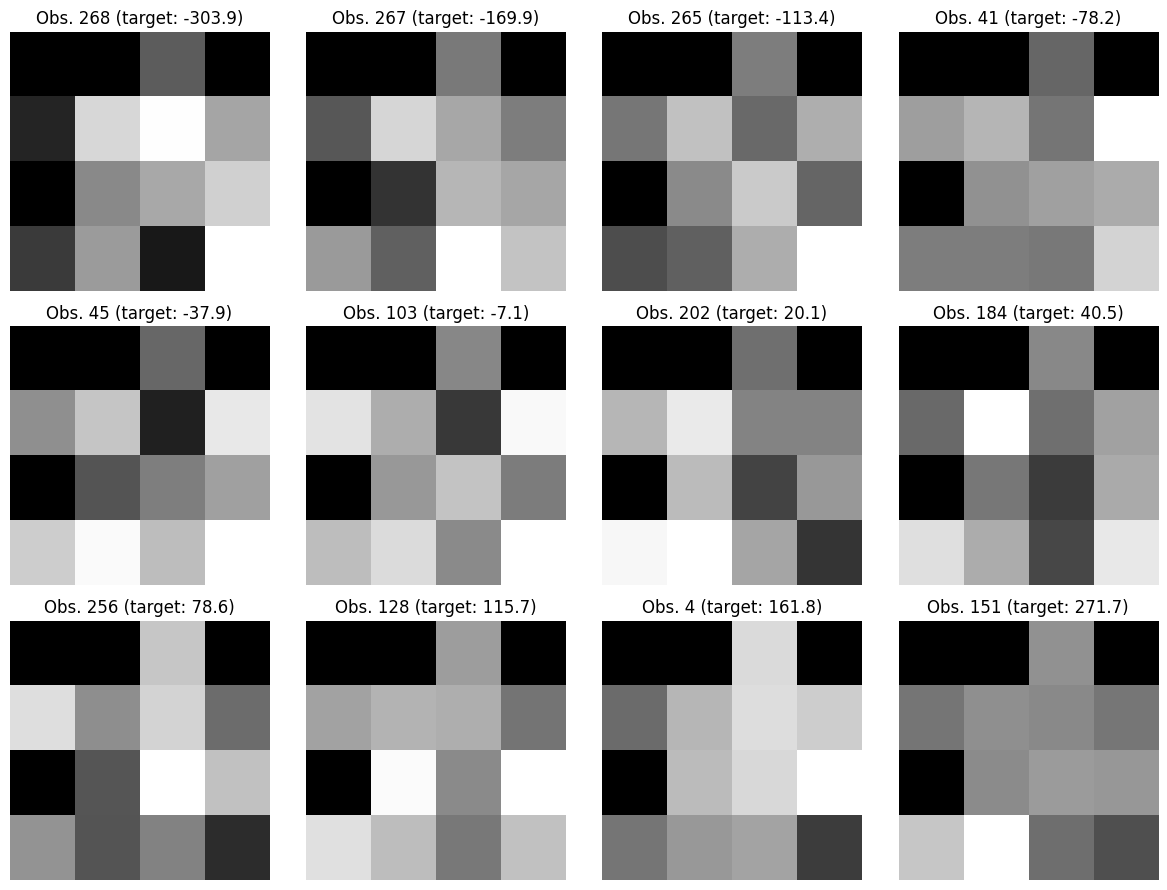

In [13]:
def cargar_imagenes(rutas):
    imagenes = []
    formas = []
    for r in rutas:
        with Image.open(r) as im:
            rgb = np.asarray(im.convert("RGB"), dtype=np.float32) / 255.0
        imagenes.append(rgb.transpose(2, 0, 1))  # PyTorch: C, H, W
        formas.append(rgb.shape[:2])
    assert len(set(formas)) == 1, "Hay imágenes de distintos tamaños; revisa el transformador"
    return torch.tensor(np.stack(imagenes))

img_tr, img_va = cargar_imagenes(rutas_tr), cargar_imagenes(rutas_va)
_, canales, ALTO, ANCHO = img_tr.shape
print(f"Imágenes: {ALTO} × {ANCHO} | canales={canales} | tensor={tuple(img_tr.shape)}")

n_mostrar = min(12, len(img_tr))
tr_reset = tr.reset_index(drop=True)

if TAREA == "classification":
    clases_unicas = tr_reset[objetivo].unique()
    por_clase = max(1, math.ceil(n_mostrar / len(clases_unicas)))
    indices = (
        tr_reset.groupby(objetivo, group_keys=False)
        .apply(lambda g: g.sample(n=min(len(g), por_clase), random_state=SEMILLA))
        .sort_values(objetivo)
        .index[:n_mostrar]
        .tolist()
    )
else:
    orden_y = tr_reset[objetivo].argsort().to_numpy()
    posiciones = np.linspace(0, len(orden_y) - 1, n_mostrar, dtype=int)
    indices = orden_y[posiciones].tolist()

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for pos, ax in enumerate(axes.flat):
    if pos < len(indices):
        idx = indices[pos]
        ax.imshow(img_tr[idx].permute(1, 2, 0).numpy(), interpolation="nearest")
        valor_target = tr_reset[objetivo].iloc[idx]
        etiqueta = f"{valor_target:.1f}" if TAREA == "regression" else f"{valor_target}"
        ax.set_title(f"Obs. {idx+1} ({objetivo}: {etiqueta})")
    ax.axis("off")
plt.tight_layout()
plt.show()

if METODO == "IGTD":
    filas, columnas = opciones["scale"]
    print("Celdas IGTD sin variable asignada:", filas * columnas - X_tr.shape[1])


<div style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:10px 14px; border-radius:5px; margin:8px 0;">
<strong>LECTURA DE LA SALIDA · La representación DeepInsight</strong><br>
Con doce variables y <code>image_dim=4</code> se obtiene una imagen de <b>4×4</b>. Según la asignación de características pueden existir posiciones vacías o colisiones. Una celda oscura no prueba por sí sola que la variable asociada carezca de valor predictivo.
<br><b>Nuevo ajuste:</b> Con <code>relocate=True</code>, la reubicación se aplica si se detectan colisiones; no implica que todas las posiciones cambien. La métrica anterior con <code>relocate=False</code> no puede atribuirse a esta nueva configuración.
</div>

<div class="alert alert-info" style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Cómo interpretar las imágenes</strong><br>
Observa patrones y espacios no utilizados, diferencias entre observaciones y dimensiones impresas. Una imagen más grande o visualmente más llamativa no demuestra mayor capacidad predictiva. Si eliges IGTD, la consola indica también cuántas celdas no representan variables.
</div>


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>


<a id="section5" name="section5"></a>
# <font color="#004D7F" size=6>5. Arquitectura CNN + MLP (fusión)</font>


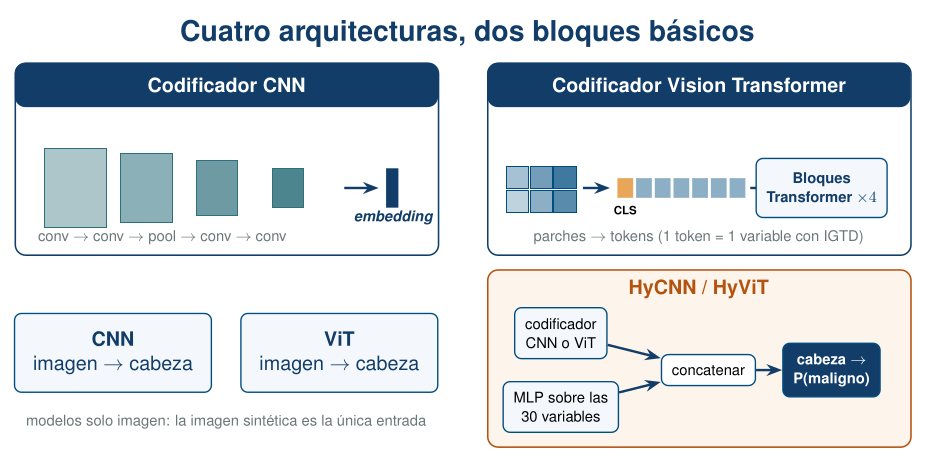

<p style="text-align:center; color:#555555;"><em><strong>Figura 5.</strong> Esquema de arquitecturas de visión e híbridas. En este notebook se implementa CNN + MLP (fusión); las demás sirven como comparación conceptual.</em></p>


**Bloque 1 · Extractor visual convolucional (`CNNSimple`)**

- **Primera capa convolucional (`Conv2d(3, 12, 3, padding=1)` + `ReLU`):** aplica $12$ filtros de tamaño $3 \times 3$ sobre los $3$ canales RGB de la imagen sintética para detectar patrones locales entre variables vecinas, manteniendo intactos el alto y el ancho originales gracias a `padding=1`.
- **Segunda capa convolucional (`Conv2d(12, 24, 3, padding=1)` + `ReLU`):** combina los $12$ mapas anteriores para construir $24$ mapas de características más abstractos sin reducir aún las dimensiones espaciales.
- **Agrupación global adaptativa (`AdaptiveAvgPool2d(1)`):** promedia todos los píxeles de cada uno de los $24$ mapas de activación para resumirlos en un único valor (`[batch, 24, 1, 1]`), lo que permite aceptar imágenes de cualquier alto o ancho sin exigir tamaños cuadrados fijos.
- **Aplanado final (`.flatten(1)`):** elimina las dimensiones espaciales unitarias ($1 \times 1$) y devuelve un vector compacto de **$24$ características visuales** (`[batch, 24]`) por cada observación del lote.


In [14]:
class CNNSimple(nn.Module):
    def __init__(self):
        super().__init__()
        self.capas = nn.Sequential(
            nn.Conv2d(3, 12, 3, padding=1), nn.ReLU(),
            nn.Conv2d(12, 24, 3, padding=1), nn.ReLU(),
            nn.AdaptiveAvgPool2d(1))

    def forward(self, x):
        return self.capas(x).flatten(1)  # [batch, 24]

**Bloque 2 · Arquitectura multimodal y estrategias de fusión (`Modelo`)**

- **Selector de estrategia (`FUSION`):** permite alternar entre concatenación (`"concat"`) y promedio (`"media"`) sin reescribir la arquitectura, facilitando la comparación experimental entre ambos mecanismos.
- **Rama visual (`self.visual`):** extrae las $24$ características mediante `CNNSimple()` y las proyecta con una capa densa (`Linear(24, 16)` + `ReLU`) a un *embedding* de **$16$ dimensiones** (`[batch, 16]`).
- **Rama tabular (`self.tabular`):** transforma las $n_{\text{tab}}$ variables numéricas originales en otro *embedding* de exactamente **$16$ dimensiones** (`Linear(n_tab, 16)` + `ReLU`), igualando el tamaño de ambas ramas para poder combinarlas directamente.
- **Fusión de modalidades en `forward(img, tab)`:**
  - Si `FUSION == "concat"`, une ambos vectores uno tras otro (`torch.cat([a, b], dim=1)`), conservando toda la información por separado en un vector de **$32$ dimensiones** (`[batch, 32]`).
  - Si `FUSION == "media"`, calcula el promedio elemento a elemento `(a + b) / 2`, condensando ambas fuentes en un único vector compartido de **$16$ dimensiones** (`[batch, 16]`).
- **Capa de salida adaptativa (`self.salida`) e instanciación:** ajusta automáticamente su dimensión de entrada ($32$ o $16$) según la fusión elegida para generar la predicción continua final (`[batch, 1]`) y traslada el modelo al `DISPOSITIVO` de cómputo.


In [15]:
FUSION = "concat"      # Alternativa: "media" (sin nuevos módulos)

class Modelo(nn.Module):
    def __init__(self, n_tab):
        super().__init__()
        self.visual = nn.Sequential(CNNSimple(), nn.Linear(24,16),nn.ReLU())
        self.tabular = nn.Sequential(nn.Linear(n_tab,16),nn.ReLU())
        self.salida = nn.Linear(32 if FUSION=="concat" else 16, 1)
    def forward(self, img, tab):
        a,b = self.visual(img), self.tabular(tab)
        unidos = torch.cat([a,b],dim=1) if FUSION=="concat" else (a+b)/2
        return self.salida(unidos)

modelo = Modelo(X_tr.shape[1]).to(DISPOSITIVO)

In [16]:
with torch.no_grad():
    salida = modelo(img_tr[:2].to(DISPOSITIVO), tab_tr[:2].to(DISPOSITIVO))
print("Entrada imágenes:", tuple(img_tr[:2].shape), "→ salida:", tuple(salida.shape))
print("Parámetros:", sum(p.numel() for p in modelo.parameters() if p.requires_grad))

Entrada imágenes: (2, 3, 4, 4) → salida: (2, 1)
Parámetros: 3593


<div class="alert alert-info" style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Qué indica la salida del modelo</strong><br>
Se muestran la forma de un pequeño lote de imágenes, la forma de la salida y el número de parámetros entrenables. Para regresión la salida tiene forma <code>(2, 1)</code>: una predicción continua por observación. El número de parámetros no es una medida de rendimiento.
</div>


**Arquitectura multimodal con módulos avanzados de fusión (`ModeloComplejo`)**

- Proyecta ambas fuentes de información a un espacio latente común de $16$ dimensiones mediante la rama visual (`CNNSimple` + proyección lineal) y la rama tabular (`Linear` + `ReLU`).
- Incorpora cuatro mecanismos avanzados de integración seleccionables mediante `FUSION`:
  - `"pesos"` (*Softmax Modality Weighting*): calcula dos pesos escalares normalizados ($w_{\text{img}} + w_{\text{tab}} = 1$) para ponderar adaptativamente cuánto contribuye cada modalidad en cada observación.
  - `"film"` (*Feature-wise Linear Modulation*): utiliza la representación tabular para generar parámetros de escala ($\gamma$) y desplazamiento ($\beta$) que modulan directamente las características extraídas de la imagen.
  - `"cross_attn"` (*Bidirectional Cross-Attention*): aplica atención cruzada en ambos sentidos (imagen $\rightarrow$ tabla y tabla $\rightarrow$ imagen) con conexiones residuales y `LayerNorm` antes de concatenar ambas representaciones enriquecidas.
  - `"transformer"` (*Multimodal Transformer Encoder*): organiza un *token* resumen `[CLS]` junto a los *embeddings* visual y tabular, añade *embeddings* de tipo de modalidad y procesa la secuencia de $3$ *tokens* mediante $2$ capas `TransformerEncoder` para extraer una representación conjunta en `[CLS]`.
- Conecta el vector fusionado resultante a un cabezal denso no lineal (`Linear` $\rightarrow$ `GELU` $\rightarrow$ `Linear`) que genera la predicción final.


In [21]:
FUSION = "transformer"  # Opciones: "pesos", "film", "cross_attn", "transformer"

class ModeloComplejo(nn.Module):
    def __init__(self, n_tab, dim=16):
        super().__init__()
        self.visual = nn.Sequential(CNNSimple(), nn.Linear(24, dim), nn.ReLU())
        self.tabular = nn.Sequential(nn.Linear(n_tab, dim), nn.ReLU())

        if FUSION == "pesos":
            # Genera 2 pesos normalizados (w_img, w_tab) que suman 1 por muestra
            self.red_pesos = nn.Sequential(
                nn.Linear(dim * 2, 16),
                nn.ReLU(),
                nn.Linear(16, 2),
                nn.Softmax(dim=1)
            )
            dim_salida = dim

        elif FUSION == "film":
            # La rama tabular genera escala (gamma) y desplazamiento (beta) para modular la visual
            self.generador_film = nn.Linear(dim, dim * 2)
            self.norm = nn.LayerNorm(dim)
            dim_salida = dim

        elif FUSION == "cross_attn":
            # Atención cruzada en ambas direcciones + normalización residual
            self.attn_img_a_tab = nn.MultiheadAttention(dim, num_heads=2, batch_first=True)
            self.attn_tab_a_img = nn.MultiheadAttention(dim, num_heads=2, batch_first=True)
            self.norm_img = nn.LayerNorm(dim)
            self.norm_tab = nn.LayerNorm(dim)
            dim_salida = dim * 2

        elif FUSION == "transformer":
            # Secuencia [CLS, img, tab] + embedding de tipo de modalidad + TransformerEncoder
            self.cls_fusion = nn.Parameter(torch.zeros(1, 1, dim))
            self.tipo_modalidad = nn.Parameter(torch.randn(1, 3, dim) * 0.02)
            capa_enc = nn.TransformerEncoderLayer(
                d_model=dim,
                nhead=2,
                dim_feedforward=dim * 4,
                dropout=0.1,
                activation="gelu",
                batch_first=True,
                norm_first=True
            )
            self.fusion_encoder = nn.TransformerEncoder(
                capa_enc, num_layers=2, enable_nested_tensor=False
            )
            self.norm = nn.LayerNorm(dim)
            dim_salida = dim

        self.salida = nn.Sequential(
            nn.Linear(dim_salida, 16),
            nn.GELU(),
            nn.Linear(16, 1)
        )

    def forward(self, img, tab):
        a = self.visual(img)   # [batch, dim]
        b = self.tabular(tab)  # [batch, dim]

        if FUSION == "pesos":
            w = self.red_pesos(torch.cat([a, b], dim=1))         # [batch, 2]
            unidos = w[:, 0:1] * a + w[:, 1:2] * b               # [batch, dim]

        elif FUSION == "film":
            gamma, beta = self.generador_film(b).chunk(2, dim=1) # Cada uno [batch, dim]
            unidos = self.norm((1.0 + gamma) * a + beta)         # [batch, dim]

        elif FUSION == "cross_attn":
            q_img, q_tab = a.unsqueeze(1), b.unsqueeze(1)        # [batch, 1, dim]
            ctx_img, _ = self.attn_img_a_tab(q_img, q_tab, q_tab)
            ctx_tab, _ = self.attn_tab_a_img(q_tab, q_img, q_img)
            a_enriq = self.norm_img(a + ctx_img.squeeze(1))
            b_enriq = self.norm_tab(b + ctx_tab.squeeze(1))
            unidos = torch.cat([a_enriq, b_enriq], dim=1)        # [batch, dim * 2]

        elif FUSION == "transformer":
            cls = self.cls_fusion.expand(a.size(0), -1, -1)      # [batch, 1, dim]
            seq = torch.stack([a, b], dim=1)                     # [batch, 2, dim]
            tokens = torch.cat([cls, seq], dim=1) + self.tipo_modalidad  # [batch, 3, dim]
            salida_enc = self.fusion_encoder(tokens)
            unidos = self.norm(salida_enc[:, 0])                 # Extrae [CLS] -> [batch, dim]

        return self.salida(unidos)

modelo = ModeloComplejo(X_tr.shape[1]).to(DISPOSITIVO)


In [22]:
with torch.no_grad():
    salida = modelo(img_tr[:2].to(DISPOSITIVO), tab_tr[:2].to(DISPOSITIVO))
print("Entrada imágenes:", tuple(img_tr[:2].shape), "→ salida:", tuple(salida.shape))
print("Parámetros:", sum(p.numel() for p in modelo.parameters() if p.requires_grad))

Entrada imágenes: (2, 3, 4, 4) → salida: (2, 1)
Parámetros: 10505


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>


<a id="section6" name="section6"></a>
# <font color="#004D7F" size=6>6. Entrenamiento y resultados</font>


PyTorch repite un ciclo sencillo: **predicción → cálculo de pérdida → gradientes → actualización de pesos**. A continuación calcula la pérdida sobre VALIDATION, que no se utiliza para actualizar parámetros.

La gráfica muestra cómo evoluciona esa pérdida durante las pocas épocas de demostración. Una curva que baja es compatible con aprendizaje, pero no prueba capacidad de generalización ni permite concluir qué transformación es la mejor.


Época 1: pérdida VALIDATION=0.8772
Época 2: pérdida VALIDATION=0.7249
Época 3: pérdida VALIDATION=0.5202
Época 4: pérdida VALIDATION=0.4181
Época 5: pérdida VALIDATION=0.4337


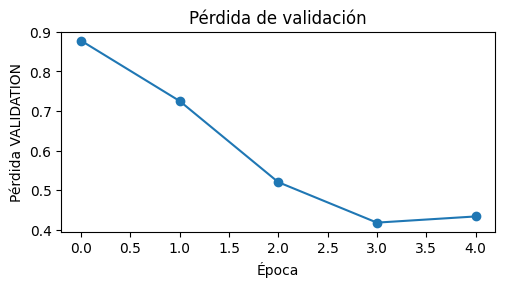

In [ ]:
train_loader = DataLoader(TensorDataset(img_tr, tab_tr, y_tr_tensor),
                          batch_size=32, shuffle=True)
val_loader = DataLoader(TensorDataset(img_va, tab_va, y_va_tensor),
                        batch_size=32)
criterio = nn.CrossEntropyLoss() if TAREA=="classification" else nn.MSELoss()
optimizador = torch.optim.Adam(modelo.parameters(),lr=1e-3)
historial = []
for epoca in range(EPOCAS):
    modelo.train()
    for img, tab, y in train_loader:
        optimizador.zero_grad()
        pred = modelo(img.to(DISPOSITIVO), tab.to(DISPOSITIVO))
        loss = criterio(pred, y.to(DISPOSITIVO).long() if TAREA=="classification"
                        else y.to(DISPOSITIVO).view(-1,1))
        loss.backward()
        optimizador.step()
    modelo.eval()
    with torch.no_grad():
        val_loss = np.mean([criterio(modelo(a.to(DISPOSITIVO),b.to(DISPOSITIVO)),
                          y.to(DISPOSITIVO).long() if TAREA=="classification"
                          else y.to(DISPOSITIVO).view(-1,1)).item()
                          for a,b,y in val_loader])
    historial.append(val_loss)
    print(f"Época {epoca+1}: pérdida VALIDATION={val_loss:.4f}")
plt.figure(figsize=(5.6,2.6))
plt.plot(historial,marker="o");plt.xlabel("Época");plt.ylabel("Loss VALIDATION")
plt.title("Pérdida de validación");plt.show()

<div style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:10px 14px; border-radius:5px; margin:8px 0;">
<strong>LECTURA DE LA SALIDA · Pérdida de VALIDATION</strong><br>
La curva ilustra cómo evoluciona la pérdida medida exclusivamente en VALIDATION. Una bajada es compatible con un mejor ajuste, pero cinco épocas no permiten afirmar convergencia. No se deben comparar valores absolutos de pérdidas de tareas o escalas distintas.
</div>

<div class="alert alert-info" style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Cómo leer la gráfica de entrenamiento</strong><br>
El eje horizontal muestra las épocas; el vertical, la pérdida calculada en VALIDATION. Valores menores suelen ser preferibles dentro de la misma tarea y escala, pero una curva corta o irregular no basta para extraer conclusiones.
</div>


La última celda traduce las predicciones en métricas fáciles de interpretar, siempre calculadas sobre **VALIDATION**. Esta evaluación es didáctica: no forma parte de un benchmark comparativo ni constituye un TEST final.


In [24]:
modelo.eval()
with torch.no_grad():
    pred = modelo(img_va.to(DISPOSITIVO), tab_va.to(DISPOSITIVO)).cpu().numpy()
if TAREA == "regression":
    estimacion = escala_y.inverse_transform(pred.reshape(-1,1)).ravel()
    real = escala_y.inverse_transform(y_va.reshape(-1,1)).ravel()
    print("MAE:",round(mean_absolute_error(real,estimacion),3),
          "| RMSE:",round(np.sqrt(mean_squared_error(real,estimacion)),3),
          "| R²:",round(r2_score(real,estimacion),3))
else:
    clases_pred = pred.argmax(axis=1)
    print("Accuracy:",round(accuracy_score(y_va,clases_pred),3),
          "| F1 macro:",round(f1_score(y_va,clases_pred,average="macro"),3))
print("Solo VALIDATION: no son resultados de un benchmark.")

MAE: 67.351 | RMSE: 83.034 | R²: 0.518
Solo VALIDATION: no son resultados de un benchmark.


<div style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:10px 14px; border-radius:5px; margin:8px 0;">
<strong>LECTURA DE LA SALIDA · Interpretación de la regresión</strong><br>
MAE y RMSE se expresan en las unidades del objetivo original; R² compara con un predictor constante de referencia. Revisa las métricas de la nueva ejecución y recuerda que <b>no son directamente comparables</b> con las del notebook 03: se utilizan problemas sintéticos diferentes.
</div>

<div class="alert alert-success" style="background-color:#e9f7f0; border-left:4px solid #2e7d61; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Cómo interpretar las métricas</strong><br>
- <strong>MAE:</strong> error absoluto medio, en unidades del objetivo original (menor es mejor).<br>- <strong>RMSE:</strong> penaliza más los errores grandes; también se expresa en unidades del objetivo (menor es mejor).<br>- <strong>R²:</strong> compara el ajuste frente a predecir siempre la media; puede ser negativo (más alto es mejor).
</div>


<div class="alert alert-warning" style="background-color:#fff7e6; border-left:4px solid #E8A65A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Lectura de esta ejecución</strong><br>
La pérdida de <b>VALIDATION</b> baja de forma sostenida, pero las métricas finales (<b>MAE ≈ 83.84</b>, <b>RMSE ≈ 109.33</b>, <b>R² ≈ 0.165</b>) muestran una mejora solo <b>moderada</b>. El modelo aprende parte de la relación objetivo, aunque todavía está lejos de un ajuste fuerte.</div>

<div class="alert alert-info" style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Qué conviene comentar en clase</strong><br>
En `DeepInsight`, activar <code>relocate=True</code> permite reorganizar variables cuando hay solapamientos potenciales. Aun así, un modelo híbrido no tiene por qué superar siempre a uno puramente visual o puramente tabular. Este notebook resulta útil para insistir en que la comparación entre métodos debe hacerse con cuidado y siempre sobre la misma partición.</div>

---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>


<a id="section7" name="section7"></a>
# <font color="#004D7F" size=6>7. Explicabilidad visual (opcional)</font>


Como actividad final, calculamos la **sensibilidad local de la predicción frente a los píxeles de una sola imagen de VALIDATION** mediante gradientes PyTorch. Es una forma sencilla de visualizar dónde el modelo responde más a cambios pequeños.

La figura tiene tres paneles: **imagen original**, **mapa de sensibilidad** y **superposición**. En las redes híbridas aparece además una barra con sensibilidades locales de la rama tabular. No se necesita instalar Captum ni implementar Grad-CAM.


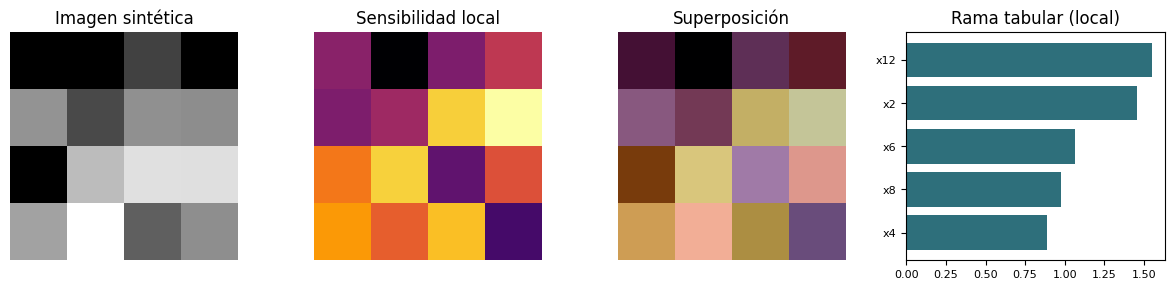

In [25]:
# OPCIONAL · Una observación de VALIDATION, sin instalar librerías nuevas.
modelo.eval()
imagen = img_va[:1].to(DISPOSITIVO).detach().clone().requires_grad_(True)
tabla = tab_va[:1].to(DISPOSITIVO).detach().clone().requires_grad_(True)
modelo.zero_grad()
prediccion = modelo(imagen, tabla)
valor = prediccion[0].max() if TAREA == "classification" else prediccion[0, 0]
valor.backward()

mapa = imagen.grad.detach().abs().mean(dim=1)[0].cpu().numpy()
original = img_va[0].permute(1, 2, 0).numpy()
grad_tab = tabla.grad  # Solo existe si la red utiliza la rama MLP.
fig, ejes = plt.subplots(1, 4 if grad_tab is not None else 3, figsize=(12, 3))
ejes[0].imshow(original); ejes[0].set_title("Imagen sintética")
ejes[1].imshow(mapa, cmap="inferno", interpolation="nearest")
ejes[1].set_title("Sensibilidad local")
ejes[2].imshow(original)
ejes[2].imshow(mapa, cmap="inferno", alpha=0.5, interpolation="nearest")
ejes[2].set_title("Superposición")
for eje in ejes[:3]: eje.axis("off")
if grad_tab is not None:
    importancia = grad_tab[0].abs().detach().cpu().numpy()
    mejores = np.argsort(importancia)[-min(5, len(importancia)):]
    nombres = [str(X_tr.columns[i])[:20] for i in mejores]
    ejes[3].barh(nombres, importancia[mejores], color="#2E6F7B")
    ejes[3].set_title("Rama tabular (local)")
    ejes[3].tick_params(labelsize=8)
plt.tight_layout(); plt.show()

<div style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:10px 14px; border-radius:5px; margin:8px 0;">
<strong>LECTURA DE LA SALIDA · Mapa de sensibilidad y fusión</strong><br>
Las tres imágenes representan el dato, la sensibilidad de salida frente a píxeles y la superposición. Las barras corresponden a gradientes locales respecto a entradas tabulares estandarizadas. <b>Ninguno de los dos mapas demuestra por sí solo qué rama aporta mayor utilidad predictiva.</b>
</div>

<div class="alert alert-warning" style="background-color:#fff6e3; border-left:4px solid #cc8a25; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Cómo interpretar esta explicación</strong><br>
Una región brillante indica <b>sensibilidad local del modelo</b>, no una causa del resultado. La barra tabular, cuando aparece, utiliza variables estandarizadas y no debe compararse directamente con los colores de la imagen. Para relacionar un píxel con una variable original hace falta el mapeo específico del transformador y comprobar su fidelidad; este ejemplo no implementa esa validación.
</div>


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>


<a id="section8" name="section8"></a>
# <font color="#004D7F" size=6>8. Conclusiones</font>


1. **El método de transformación es una decisión importante:** con DeepInsight, una observación de regresión sintética controlada se convierte en una imagen cuya estructura debe interpretarse.
2. **No hay fuga de información:** la transformación y los escaladores se ajustan solo en TRAIN, y VALIDATION reutiliza ese estado.
3. **La arquitectura se entiende por su recorrido de tensores:** imagen (y tabla, si hay MLP), extractor, fusión si corresponde y predicción.
4. **Las salidas muestran lo que ha ocurrido en este ensayo:** tamaños, imágenes, pérdida y métricas de validación, no una conclusión científica general.
5. **Explicabilidad como primer contacto:** los mapas locales son ilustrativos; no prueban causalidad ni fidelidad.

Una red híbrida combina características visuales y tabulares, pero su existencia no demuestra que supere a una CNN o un modelo tabular: eso requiere comparaciones controladas.


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>


<a id="section9" name="section9"></a>
# <font color="#004D7F" size=6>9. Ejercicios</font>


<div class="alert alert-info" style="background-color:#eaf6fb; border-left:4px solid #00838A; padding:12px 15px; border-radius:5px; margin:12px 0;">
<strong>Trabajo propuesto · 10 minutos.</strong><br>
Realiza uno o dos cambios pequeños y describe las imágenes y las salidas, no solo el valor de la métrica.
</div>

1. **Compara representaciones.** Cambia `METODO` por otro de la tabla y vuelve a ejecutar desde la configuración. ¿Qué cambia en la forma y apariencia de las imágenes?
2. **Interpreta la salida.** Explica con tus palabras qué representan el tensor de entrada, la predicción y MAE/RMSE/R².
3. Cambia `FUSION` entre `"concat"` y `"media"`. ¿Qué cambia en el tamaño de la entrada de la última capa? No interpretes una sola diferencia en MAE como una mejora estable.
4. **Relocalización (opcional).** Cambia `"relocate": True` por `False` y compara las imágenes generadas. ¿La nueva geometría modifica la salida de la red?
5. **Opcional, explicabilidad.** Observa el mapa de sensibilidad local. ¿Qué muestra realmente? ¿Por qué no demuestra causalidad?

<b>Continuación:</b> el notebook **06 · TINTOlib hands-on v3 (ES)** amplía el estudio con más métodos de transformación, evaluación rigurosa y técnicas XAI de mayor profundidad.


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>


<a id="section10" name="section10"></a>
# <font color="#004D7F" size=6>10. Referencias</font>


- **TINTOlib**. [Repositorio de Python](https://github.com/oeg-upm/TINTOlib) · [Documentación de la biblioteca](https://tintolib.readthedocs.io/en/latest/).
- **TINTO**. Castillo-Cara et al. (2023). *TINTO: Converting Tidy Data into Image for Classification with 2-D Convolutional Neural Networks*. [SoftwareX](https://doi.org/10.1016/j.softx.2023.101391).
- **TINTOlib**. Liu et al. (2025). *TINTOlib: A Python library for transforming tabular data into synthetic images for deep neural networks*. [SoftwareX](https://doi.org/10.1016/j.softx.2025.102444).
- **Benchmark de codificadores**. Liu et al. (2026). *A comprehensive benchmark of spatial encoding methods for tabular data with deep neural networks*. [Information Fusion](https://doi.org/10.1016/j.inffus.2025.104088).
- **PyTorch**. [nn.Module](https://pytorch.org/docs/stable/generated/torch.nn.Module.html) · [TransformerEncoderLayer](https://pytorch.org/docs/stable/generated/torch.nn.TransformerEncoderLayer.html).
- **Recursos adicionales**. [TINTOlib Crash Course](https://github.com/oeg-upm/TINTOlib-Crash_Course) · [Blog de tutoriales](https://www.manuelcastillo.eu/blog/) · Notebook **06 TINTOlib_hands_on_v3_ES** (material avanzado que se entrega al final).


---
<div style="text-align: right">
<font size=5>
<a href="#indice">Volver al índice</a>
</font>
</div>
